<a href="https://colab.research.google.com/github/dhyun16/ESAA/blob/main/%EA%B9%80%EB%91%90%ED%98%84_1120_%EC%97%B0%EC%8A%B5%EB%AC%B8%EC%A0%9C_%ED%9A%8C%EA%B7%802.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **1. 규제 선형 회귀 모델/ 회귀 트리**
- 릿지 회귀모델 및 회귀 트리를 이용하여 전복의 나이를 예측해 보세요.

- 전복의 ‘성별’, ‘키’, ‘지름’, ‘높이’, ‘전체무게’, ‘몸통무게’, ‘내장무게’, ‘껍질무게’를 이용해 ‘껍질의 고리수’를 예측한 뒤, **예측된 ‘껍질의 고리수’에 1.5를 더하면 전복의 나이**가 됩니다.

In [48]:
# 기본 모듈 불러오기
import numpy as np
import pandas as pd

import warnings
warnings.filterwarnings(action='ignore')

### 1) 데이터 불러오기 및 데이터 선택

In [49]:
# 데이터 로드
data = pd.read_csv("abalone.csv")

# 성별 M은 Male, F는 Female, I는 Infant 이므로 따로 열 만들기
for label in "MFI":
    data[label] = data["Sex"] == label
data.drop('Sex', axis=1, inplace=True)

# X,y 데이터 선택
y = data.Rings.values
data.drop('Rings', axis=1, inplace=True)

X = data.values.astype(float)

## 2) train/test 분리
: 테스트 셋과 데이터 셋을 7:3 비율로 분리하세요.

In [50]:
# 필요한 모듈 불러오기
from sklearn.model_selection import train_test_split

In [51]:
# train과 test set 분리 (train:test = 7:3 비율로)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=156
)

## 3) 릿지 모델을 이용한 모델링
: 릿지 모델을 이용하여 전복의 나이를 예측해 보고 결과를 평가해 보세요.

 3-1) 릿지모델 생성, 교차검증, 평가에 필요한 모듈을 불러오세요.

In [52]:
#필요한 모듈 불러오기
from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_val_score
from sklearn.metrics import mean_squared_error

3-2) 릿지 모델을 생성하고 훈련하여 MSE와 RMSE를 구하세요. 릿지 모델 생성 시  alpha는 0.3으로 설정합니다. (교차 검증 하지 않습니다.)

In [53]:
#릿지모델 생성 및 훈련
ridge_reg = Ridge(alpha=0.3)
ridge_reg.fit(X_train, y_train)

#예측값 구하기
pred_rings = ridge_reg.predict(X_test)
pred_age = pred_rings + 1.5

#구한 예측값을 활용해 최종적으로 전복의 나이 예측
actual_age = y_test + 1.5


#MSE와 RMSE구하기
mse = mean_squared_error(actual_age, pred_age)
rmse = np.sqrt(mse)

3-3) 릿지 모델에서 회귀 계수 값을 구해 알 수 있는 점을 작성하시오. (각 컬럼의 정보는 data.colums 참고)

In [54]:
data.columns

Index(['Length', 'Diameter', 'Height', 'Whole weight', 'Shucked weight',
       'Viscera weight', 'Shell weight', 'M', 'F', 'I'],
      dtype='object')

- 각 피처가 Rings(및 전복 나이)에 미치는 선형적 영향력의 방향(+)과 크기를 확인할 수 있음  


3-3) 교차검증을 이용하여 0, 0.1, 1, 10, 100 중  모델 성능이 가장 좋게 나오는 (rmse가 최소가 되는) alpha를 구하세요.

In [55]:
# 주어진 alpha
alphas=[0, 0.1, 1, 10, 100]

In [56]:
#alphas list 값을 반복하면서 alpha에 따른 평균 rmse를 구함
for alpha in alphas:
    ridge_cv = Ridge(alpha=alpha)

  #cross_val_score를 이용해 5 폴드의 평균 RMSE를 계산
    neg_mse_scores = cross_val_score(
        ridge_cv, X_train, y_train, scoring="neg_mean_squared_error", cv=5
    )
    avg_rmse = np.mean(np.sqrt(-1 * neg_mse_scores))
    print(f"alpha: {alpha:<5} | 5-Fold 평균 RMSE: {avg_rmse:.4f}")

alpha: 0     | 5-Fold 평균 RMSE: 2.1937
alpha: 0.1   | 5-Fold 평균 RMSE: 2.1933
alpha: 1     | 5-Fold 평균 RMSE: 2.2123
alpha: 10    | 5-Fold 평균 RMSE: 2.3651
alpha: 100   | 5-Fold 평균 RMSE: 2.6253


## 4) XGBRegressor을 이용한 모델링
: XGBRegressor 모델을 이용하여 전복의 나이를 예측해 보고 결과를 평가해 보세요.

4-1) XGBRegressor 훈련, 평가에 필요한 모듈을 불러오세요.

In [57]:
# 필요한 모듈 임포트
from xgboost import XGBRegressor
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

4-2) XGBregressor 모델을 생성하고 훈련하여 MSE와 RMSE를 구하세요.

In [58]:
#모델 생성 및 훈련
xgb_reg = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=156
)
xgb_reg.fit(X_train, y_train)

#예측값 구하기
xgb_pred_rings = xgb_reg.predict(X_test)
xgb_pred_age = xgb_pred_rings + 1.5


#구한 예측값을 활용해 최종적으로 전복의 나이 예측
actual_age = y_test + 1.5

#MSE와 RMSE 구하기
xgb_mse = mean_squared_error(actual_age, xgb_pred_age)
xgb_rmse = np.sqrt(xgb_mse)

print(f"XGBRegressor MSE: {xgb_mse:.4f}, RMSE: {xgb_rmse:.4f}")


XGBRegressor MSE: 4.7317, RMSE: 2.1752


4-3) 생성한 모델의 피처 중요도를 시각화해보세요.

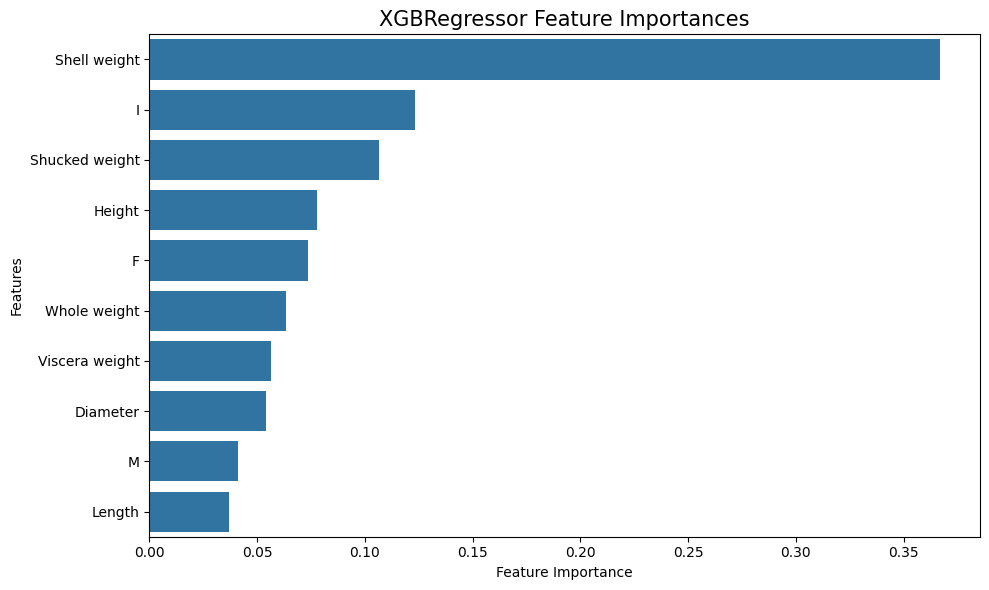

In [60]:
import seaborn as sns
%matplotlib inline
feature_cols = data.columns
ftr_importances_values = xgb_reg.feature_importances_
ftr_importances = pd.Series(ftr_importances_values, index=feature_cols)
ftr_top = ftr_importances.sort_values(ascending=False)

plt.figure(figsize=(10, 6))
plt.title('XGBRegressor Feature Importances', size=15)
sns.barplot(x=ftr_top.values, y=ftr_top.index)
plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.tight_layout()
plt.show()


---

# **2. 로지스틱 회귀분석**
load_wine() 함수를 이용하여 와인 데이터를 다항분류하는 로지스틱 회귀모델을 생성하세요.

In [61]:
# 필요한 모듈 불러오기
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

## 1) 데이터 불러오기 및 변수 선택

In [62]:
wine = load_wine()

wine_x = wine.data # x변수
wine_y = wine.target # y변수

## 2) train/test 셋 분리

In [63]:
x_train, x_test, y_train, y_test = train_test_split(wine_x, wine_y, test_size=0.3, random_state=123)

x_train.shape
y_train.shape

(124,)

## 3) 로지스틱 회귀모델을 이용한 모델링

3-1) 로지스틱 회귀모델을 생성하여 훈련하세요.

In [64]:
lr_clf = LogisticRegression(max_iter=5000, random_state=123)
lr_clf.fit(x_train, y_train)

LogisticRegression(max_iter=5000, random_state=123)

3-2) 회귀 모델의 기울기와 절편을 구하세요.

In [66]:
#기울기
lr_clf.coef_

기울기(coef_):
 [[ 5.40119857e-01  5.55141609e-01  6.20476859e-01 -2.58233732e-01
  -1.45090139e-04  2.55690914e-01  7.52039277e-01  8.78394493e-02
   1.63790241e-01  1.96653394e-01  1.22113689e-02  5.19222294e-01
   8.77112451e-03]
 [-6.96442843e-01 -9.22500438e-01 -7.03121269e-01  1.51118933e-01
  -4.31236620e-02  3.12399569e-01  1.59485268e-01  1.17931800e-02
   3.72214630e-01 -9.37234424e-01  2.86879368e-01  1.35291197e-01
  -7.77953721e-03]
 [ 1.56322986e-01  3.67358828e-01  8.26444092e-02  1.07114799e-01
   4.32687521e-02 -5.68090483e-01 -9.11524545e-01 -9.96326293e-02
  -5.36004871e-01  7.40581030e-01 -2.99090737e-01 -6.54513491e-01
  -9.91587312e-04]]


In [67]:
#절편
lr_clf.intercept_

array([-15.57767711,  22.74821606,  -7.17053895])

3-3) 모델의 정확도를 구하세요.

In [69]:
#모델의 예측값 구하기
y_pred = lr_clf.predict(x_test)

#모델의 정확도 구하기
accuracy = metrics.accuracy_score(y_test, y_pred)
print(accuracy)

0.9629629629629629
